In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Datasets
from sklearn.datasets import load_iris

# Preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer

# Train-Test Split & Cross Validation
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

# ✅ Three Naive Bayes Models
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB

# Evaluation
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [ ]:

np.random.seed(42)
n = 200

data = {
    'pclass':    np.random.randint(1, 4, n),
    'sex':       np.random.choice(['male', 'female'], n),
    'age':       np.random.randint(1, 80, n).astype(float),
    'sibsp':     np.random.randint(0, 5, n),
    'parch':     np.random.randint(0, 5, n),
    'fare':      np.round(np.random.uniform(5, 100, n), 2),
    'embarked':  np.random.choice(['S', 'C', 'Q'], n),
    'survived':  np.random.choice([0, 1], n, p=[0.3, 0.7])
}

df = pd.DataFrame(data)

print(df.head(10))

   pclass     sex   age  sibsp  parch   fare embarked  survived
0       3  female  64.0      3      2  93.01        Q         0
1       1    male  49.0      3      2  73.55        S         1
2       3  female  17.0      2      3   9.57        C         0
3       3    male  44.0      1      1  79.24        Q         1
4       1  female  30.0      4      1  83.65        S         1
5       1  female  46.0      4      1  76.30        C         1
6       3  female   6.0      2      1  80.96        S         1
7       2  female  37.0      3      2  83.39        C         1
8       3    male  24.0      0      2  22.71        S         1
9       3  female  46.0      3      1  27.39        S         1


In [ ]:
df = pd.DataFrame(data)

print(df.head(10))

for col in ['age', 'fare']:
    df.loc[df.sample(frac=0.1).index, col] = np.nan

print(df.isnull().sum())


   pclass     sex   age  sibsp  parch   fare embarked  survived
0       3  female  64.0      3      2  93.01        Q         0
1       1    male  49.0      3      2  73.55        S         1
2       3  female  17.0      2      3   9.57        C         0
3       3    male  44.0      1      1  79.24        Q         1
4       1  female  30.0      4      1  83.65        S         1
5       1  female  46.0      4      1  76.30        C         1
6       3  female   6.0      2      1  80.96        S         1
7       2  female  37.0      3      2  83.39        C         1
8       3    male  24.0      0      2  22.71        S         1
9       3  female  46.0      3      1  27.39        S         1
pclass       0
sex          0
age         20
sibsp        0
parch        0
fare        20
embarked     0
survived     0
dtype: int64


In [ ]:
df['age'] = df['age'].fillna(df['age'].median())
df['fare'] = df['fare'].fillna(df['fare'].median())

print(df.isnull().sum())

pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
survived    0
dtype: int64


In [ ]:
df['sex'] = df['sex'].map({'male': 1, 'female': 0})

df['embarked'] = df['embarked'].map({'S': 2, 'C': 0, 'Q': 1})

print(df.head())


   pclass  sex   age  sibsp  parch   fare  embarked  survived
0       3    0  34.5      3      2  93.01         1         0
1       1    1  49.0      3      2  73.55         2         1
2       3    0  17.0      2      3   9.57         0         0
3       3    1  44.0      1      1  79.24         1         1
4       1    0  30.0      4      1  83.65         2         1


In [ ]:
X = df[['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']]
y = df['survived']

print(X.head())
print(y.head())

   pclass  sex   age  sibsp  parch   fare  embarked
0       3    0  34.5      3      2  93.01         1
1       1    1  49.0      3      2  73.55         2
2       3    0  17.0      2      3   9.57         0
3       3    1  44.0      1      1  79.24         1
4       1    0  30.0      4      1  83.65         2
0    0
1    1
2    0
3    1
4    1
Name: survived, dtype: int64


In [ ]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset:")
print(df.head(10))

Dataset shape: (200, 8)

Missing values:
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
survived    0
dtype: int64

Dataset:
   pclass  sex   age  sibsp  parch   fare  embarked  survived
0       3    0  34.5      3      2  93.01         1         0
1       1    1  49.0      3      2  73.55         2         1
2       3    0  17.0      2      3   9.57         0         0
3       3    1  44.0      1      1  79.24         1         1
4       1    0  30.0      4      1  83.65         2         1
5       1    0  46.0      4      1  76.30         0         1
6       3    0   6.0      2      1  57.65         2         1
7       2    0  37.0      3      2  83.39         0         1
8       3    1  24.0      0      2  22.71         2         1
9       3    0  34.5      3      1  27.39         2         1


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (160, 7)
Testing data: (40, 7)


      MULTINOMIAL NAIVE BAYES RESULTS
Training Accuracy : 0.6875
Testing  Accuracy : 0.8000

Classification Report:
                 precision    recall  f1-score   support

Did not survive       0.00      0.00      0.00         8
       Survived       0.80      1.00      0.89        32

       accuracy                           0.80        40
      macro avg       0.40      0.50      0.44        40
   weighted avg       0.64      0.80      0.71        40



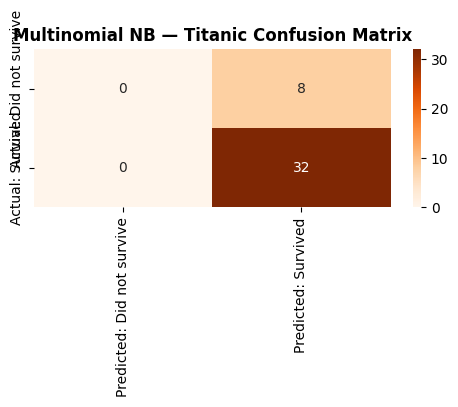

In [ ]:
# MultinomialNB requires non-negative features → use MinMaxScaler
mm_scaler = MinMaxScaler()

X_train_mm = mm_scaler.fit_transform(X_train)
X_test_mm = mm_scaler.transform(X_test)


# Train
mnb = MultinomialNB()
mnb.fit(X_train_mm, y_train)

# Use the trained model as "model"
model = mnb


# Predict
y_pred_mnb = mnb.predict(X_test_mm)


# Evaluate
print("=" * 45)
print("      MULTINOMIAL NAIVE BAYES RESULTS")
print("=" * 45)

print(f"Training Accuracy : {accuracy_score(y_train, mnb.predict(X_train_mm)):.4f}")
print(f"Testing  Accuracy : {accuracy_score(y_test, y_pred_mnb):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_mnb,
    target_names=['Did not survive', 'Survived']
))


# Confusion Matrix
cm_mnb = confusion_matrix(y_test, y_pred_mnb)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm_mnb,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Predicted: Did not survive', 'Predicted: Survived'],
    yticklabels=['Actual: Did not survive', 'Actual: Survived']
)

plt.title('Multinomial NB — Titanic Confusion Matrix', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:

# Ask the user for passenger details

print("Enter passenger information:")

pclass = int(input("Pclass (1, 2, or 3): "))

sex = int(input("Sex (1 = male, 0 = female): "))

age = float(input("Age: "))

sibsp = int(input("SibSp: "))

parch = int(input("Parch: "))

fare = float(input("Fare: "))

embarked = int(input("Embarked ( 2= S,  0= C, 1 = Q): "))


# Create a DataFrame with the user input

new_passenger = pd.DataFrame([{
    'pclass': pclass,
    'sex': sex,
    'age': age,
    'sibsp': sibsp,
    'parch': parch,
    'fare': fare,
    'embarked': embarked
}])


# Get prediction and confidence

prediction = model.predict(new_passenger)[0]

probabilities = model.predict_proba(new_passenger)[0]

confidence = max(probabilities) * 100


# Display the result

print(f"\nPrediction: {'Survived' if prediction == 1 else 'Did not survive'}")

print(f"Confidence: {confidence:.2f}%")

print(f"Probability breakdown: {dict(zip(model.classes_, probabilities))}")

Enter passenger information:
Fare: 20
